# Deepfake Detection: Exploratory Data Analysis

**Goal:** understand the two datasets used in the project before training and evaluating any model.

| Dataset | Content | Original resolution |
|---|---|---|
| **CIFAKE** | Real photos (CIFAR-10 style objects/animals) vs AI-generated images | 32 x 32 |
| **140k Real and Fake Faces** | Real faces (Flickr) vs StyleGAN-generated faces | 256 x 256 |

**Questions this notebook answers**
1. How is each dataset organised (splits, classes, balance)?
2. What do the images look like (size, format, colour mode)?
3. Do real and fake images differ in simple statistics (brightness, colour, file size, frequency content)?
4. Are there biases or shortcuts a model could exploit instead of learning real artifacts?

**Convention used everywhere in the project:** label `0 = fake`, label `1 = real`.

## 1. Setup

In [2]:
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")

# Project paths (fall back to local folders if the package is not installed)
try:
    from deepfake_detection.config import DATA_RAW, DATA_PROCESSED, SEED
except ImportError:
    DATA_RAW = Path("data/raw")
    DATA_PROCESSED = Path("data/processed")
    SEED = 42

random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
COLORS = {"fake": "#d6453d", "real": "#2e7d5b"}   # consistent colours: fake = red, real = green

print("DATA_RAW      :", DATA_RAW)
print("DATA_PROCESSED:", DATA_PROCESSED)
print("SEED          :", SEED)

DATA_RAW      : C:\Users\21624\Desktop\deepfake_detection\data\raw
DATA_PROCESSED: C:\Users\21624\Desktop\deepfake_detection\data\processed
SEED          : 42


In [4]:
# Dataset locations (adapt the sub-folders if your layout differs)
DATASETS = {
    "CIFAKE": DATA_RAW / "images ai vs real",
    "Faces":  DATA_RAW / "Facesai vs real" / "real_vs_fake" / "real-vs-fake",
}
IMG_EXT = {".jpg", ".jpeg", ".png"}

for name, root in DATASETS.items():
    status = "OK" if root.exists() else "NOT FOUND"
    splits = sorted(p.name for p in root.iterdir() if p.is_dir()) if root.exists() else []
    print(f"{name:7s} [{status}] {root}")
    print(f"        splits: {splits}")

CIFAKE  [OK] C:\Users\21624\Desktop\deepfake_detection\data\raw\images ai vs real
        splits: ['test', 'train']
Faces   [OK] C:\Users\21624\Desktop\deepfake_detection\data\raw\Facesai vs real\real_vs_fake\real-vs-fake
        splits: ['test', 'train', 'valid']


## 2. Dataset inventory

We scan every folder once and build a single table with one row per image
(`dataset`, `split`, `label`, `path`). All later steps reuse this table.

In [6]:
def build_inventory(name, root):
    rows = []
    for split_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        for cls_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for f in cls_dir.rglob("*"):
                if f.suffix.lower() in IMG_EXT:
                    rows.append((name, split_dir.name.lower(), cls_dir.name.lower(), str(f)))
    return pd.DataFrame(rows, columns=["dataset", "split", "label", "path"])

inventory = pd.concat([build_inventory(n, r) for n, r in DATASETS.items()], ignore_index=True)

print(f"Total images indexed: {len(inventory):,}")
display(inventory.head())

Total images indexed: 260,000


,dataset,split,label,path
0,CIFAKE,test,fake,C:\Users\21624\Desktop\deepfake_detection\data...
1,CIFAKE,test,fake,C:\Users\21624\Desktop\deepfake_detection\data...
2,CIFAKE,test,fake,C:\Users\21624\Desktop\deepfake_detection\data...
3,CIFAKE,test,fake,C:\Users\21624\Desktop\deepfake_detection\data...
4,CIFAKE,test,fake,C:\Users\21624\Desktop\deepfake_detection\data...


### 2.1 Images per split and class

In [8]:
counts = pd.crosstab([inventory["dataset"], inventory["split"]], inventory["label"], margins=True, margins_name="total")
display(counts)

label            fake    real   total
dataset split                        
CIFAKE  test    10000   10000   20000
        train   50000   50000  100000
Faces   test    10000   10000   20000
        train   50000   50000  100000
        valid   10000   10000   20000
total          130000  130000  260000

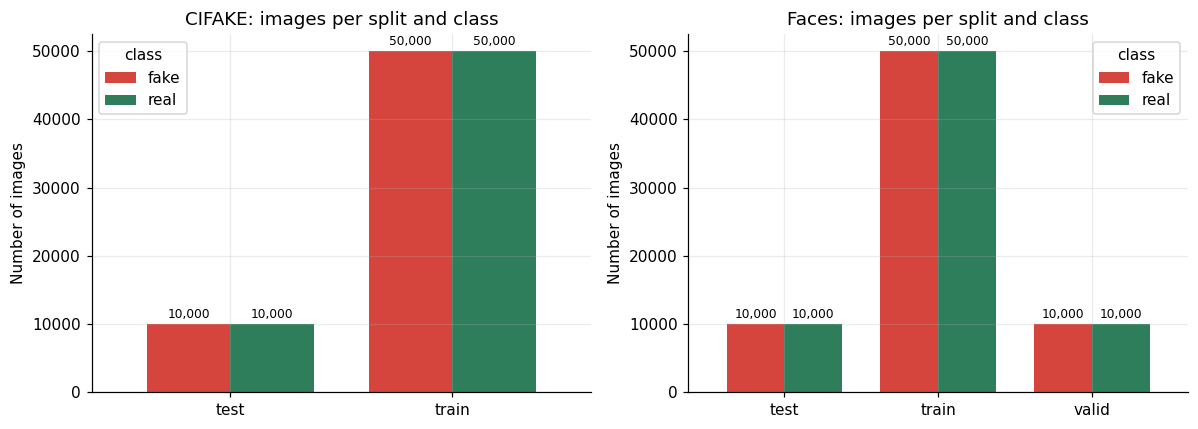

In [10]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 4))
axes = np.atleast_1d(axes)

for ax, (name, _) in zip(axes, DATASETS.items()):
    sub = inventory[inventory["dataset"] == name]
    table = pd.crosstab(sub["split"], sub["label"])
    table.plot(kind="bar", ax=ax, color=[COLORS.get(c, "grey") for c in table.columns], rot=0, width=0.75)
    ax.set_title(f"{name}: images per split and class")
    ax.set_xlabel("")
    ax.set_ylabel("Number of images")
    ax.legend(title="class")
    for container in ax.containers:
        ax.bar_label(container, fmt="{:,.0f}", fontsize=8, padding=2)

plt.tight_layout()
plt.show()

In [12]:
# Class balance (imbalance ratio = majority / minority, 1.00 means perfectly balanced)
balance = (inventory.groupby(["dataset", "split", "label"]).size()
           .unstack("label").fillna(0))
balance["imbalance_ratio"] = balance.max(axis=1) / balance.min(axis=1)
display(balance.round(2))

label           fake   real  imbalance_ratio
dataset split                               
CIFAKE  test   10000  10000              1.0
        train  50000  50000              1.0
Faces   test   10000  10000              1.0
        train  50000  50000              1.0
        valid  10000  10000              1.0

## 3. Image properties

We open a random sample (files are read lazily, so only the header is decoded) to check
**resolution, colour mode, format and file size** for each dataset and class.

In [14]:
import os

N_PROPS = 400   # images per (dataset, label)

def sample_paths(dataset, label, n, split=None):
    sub = inventory[(inventory["dataset"] == dataset) & (inventory["label"] == label)]
    if split:
        sub = sub[sub["split"] == split]
    return sub["path"].sample(min(n, len(sub)), random_state=SEED).tolist()

records = []
for dataset in DATASETS:
    for label in ["fake", "real"]:
        for p in sample_paths(dataset, label, N_PROPS):
            with Image.open(p) as im:
                records.append({
                    "dataset": dataset, "label": label,
                    "width": im.size[0], "height": im.size[1],
                    "mode": im.mode, "format": im.format,
                    "size_kb": os.path.getsize(p) / 1024,
                })
props = pd.DataFrame(records)

display(props.groupby(["dataset", "label"]).agg(
    width_min=("width", "min"), width_max=("width", "max"),
    height_min=("height", "min"), height_max=("height", "max"),
    modes=("mode", lambda s: ", ".join(sorted(s.unique()))),
    formats=("format", lambda s: ", ".join(sorted(s.unique()))),
    size_kb_mean=("size_kb", "mean"),
).round(2))

width_min  width_max  height_min  height_max modes formats  \
dataset label                                                               
CIFAKE  fake          32         32          32          32   RGB    JPEG   
        real          32         32          32          32   RGB    JPEG   
Faces   fake         256        256         256         256   RGB    JPEG   
        real         256        256         256         256   RGB    JPEG   

               size_kb_mean  
dataset label                
CIFAKE  fake           0.89  
        real           0.90  
Faces   fake          27.73  
        real          28.06

In [16]:
# Most common resolutions
res = (props.assign(resolution=props["width"].astype(str) + "x" + props["height"].astype(str))
            .groupby(["dataset", "label", "resolution"]).size().rename("count").reset_index())
display(res.sort_values(["dataset", "label", "count"], ascending=[True, True, False]))

,dataset,label,resolution,count
0,CIFAKE,fake,32x32,400
1,CIFAKE,real,32x32,400
2,Faces,fake,256x256,400
3,Faces,real,256x256,400


### 3.1 File size by class

A file-size gap between fake and real images is a classic **dataset bias**: a model can exploit it
(for example through JPEG compression differences) without learning anything about the generation artifacts.

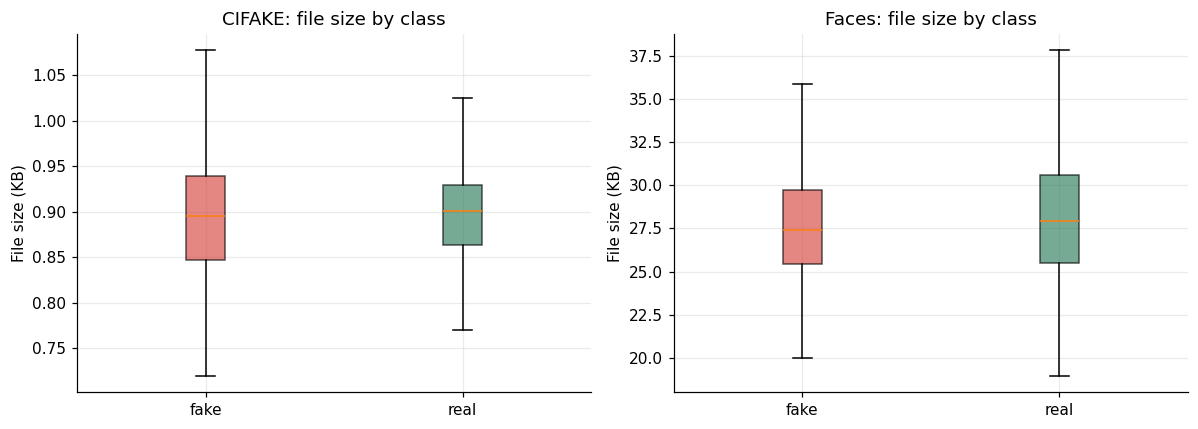

In [18]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 4))
axes = np.atleast_1d(axes)

for ax, dataset in zip(axes, DATASETS):
    data = [props[(props.dataset == dataset) & (props.label == l)]["size_kb"] for l in ["fake", "real"]]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    ax.set_xticklabels(["fake", "real"])
    for patch, l in zip(bp["boxes"], ["fake", "real"]):
        patch.set_facecolor(COLORS[l]); patch.set_alpha(0.65)
    ax.set_title(f"{dataset}: file size by class")
    ax.set_ylabel("File size (KB)")

plt.tight_layout()
plt.show()

## 4. Visual samples

Random images from the **training** split, one row per class.
Look for visible artifacts in the fake row (texture, symmetry, background, hair, eyes).

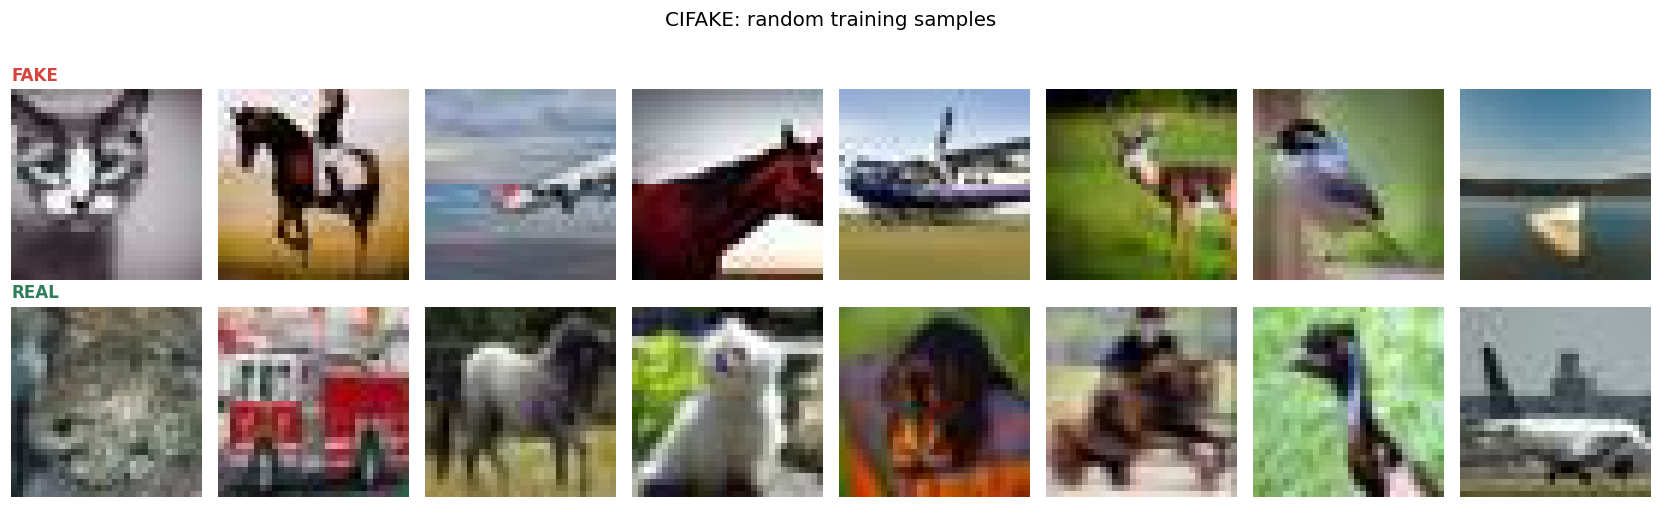

In [20]:
def show_samples(dataset, n=8, split="train", seed=SEED):
    fig, axes = plt.subplots(2, n, figsize=(1.9 * n, 4.6))
    for r, label in enumerate(["fake", "real"]):
        paths = inventory[(inventory.dataset == dataset) & (inventory.label == label) & (inventory.split == split)]["path"]
        chosen = paths.sample(min(n, len(paths)), random_state=seed + r).tolist()
        for c in range(n):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(chosen):
                ax.imshow(Image.open(chosen[c]).convert("RGB"))
            if c == 0:
                ax.set_title(label.upper(), loc="left", fontsize=11, fontweight="bold", color=COLORS[label])
    fig.suptitle(f"{dataset}: random training samples", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

show_samples("CIFAKE")

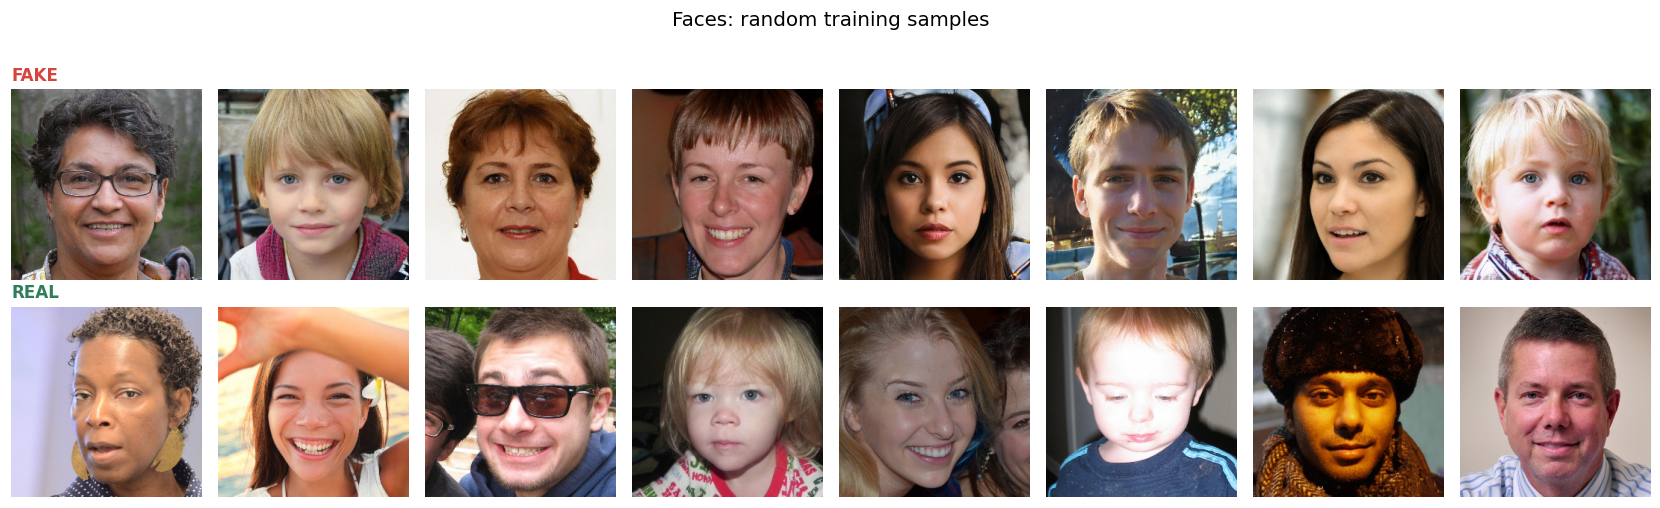

In [22]:
show_samples("Faces")

### 4.1 Same images, as the model sees them

Before training, every image is resized to **128 x 128** (`TRANSFORM` in `utils.py`).
CIFAKE images (32 x 32) are **upscaled 4x**, which adds no new detail but blurs the original pixels.
This is important when interpreting the cross-dataset results.

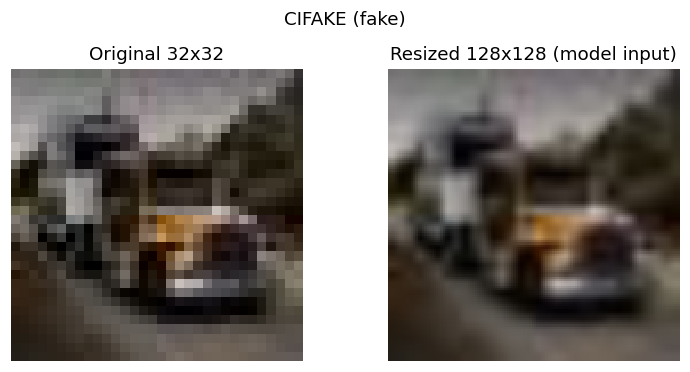

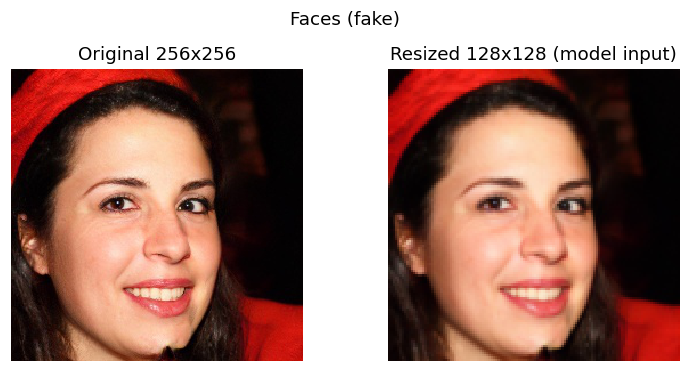

In [24]:
def compare_resolution(dataset, label="fake", split="train"):
    p = inventory[(inventory.dataset == dataset) & (inventory.label == label) & (inventory.split == split)]["path"].iloc[0]
    img = Image.open(p).convert("RGB")
    resized = img.resize((128, 128), Image.BILINEAR)
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
    axes[0].imshow(img, interpolation="nearest"); axes[0].set_title(f"Original {img.size[0]}x{img.size[1]}")
    axes[1].imshow(resized, interpolation="nearest"); axes[1].set_title("Resized 128x128 (model input)")
    for ax in axes: ax.axis("off")
    fig.suptitle(f"{dataset} ({label})")
    plt.tight_layout(); plt.show()

for d in DATASETS:
    compare_resolution(d)

## 5. Pixel statistics

We load a balanced sample of images at 128 x 128 (the model input size) into memory
and compare **colour channels and brightness** between fake and real images.

In [26]:
N_PIX = 300   # images per (dataset, label)

def load_array(paths, size=(128, 128)):
    return np.stack([np.asarray(Image.open(p).convert("RGB").resize(size, Image.BILINEAR)) for p in paths]).astype(np.float32)

arrays = {}
for dataset in DATASETS:
    for label in ["fake", "real"]:
        arrays[(dataset, label)] = load_array(sample_paths(dataset, label, N_PIX, split="train"))
        print(f"{dataset:7s} {label}: {arrays[(dataset, label)].shape}")

CIFAKE  fake: (300, 128, 128, 3)
CIFAKE  real: (300, 128, 128, 3)
Faces   fake: (300, 128, 128, 3)
Faces   real: (300, 128, 128, 3)


In [28]:
rows = []
for (dataset, label), arr in arrays.items():
    rows.append({
        "dataset": dataset, "label": label,
        "mean_R": arr[..., 0].mean(), "mean_G": arr[..., 1].mean(), "mean_B": arr[..., 2].mean(),
        "std_R": arr[..., 0].std(),  "std_G": arr[..., 1].std(),  "std_B": arr[..., 2].std(),
        "brightness": arr.mean(),
    })
display(pd.DataFrame(rows).set_index(["dataset", "label"]).round(2))

mean_R      mean_G      mean_B      std_R      std_G  \
dataset label                                                             
CIFAKE  fake   115.570000  113.230003   98.639999  55.889999  55.860001   
        real   123.989998  121.379997  111.129997  61.939999  61.000000   
Faces   fake   132.880005  110.449997   99.300003  69.879997  64.050003   
        real   128.960007  104.110001   93.180000  70.330002  62.740002   

                   std_B  brightness  
dataset label                         
CIFAKE  fake   66.820000  109.150002  
        real   64.300003  118.839996  
Faces   fake   64.169998  114.209999  
        real   62.680000  108.750000

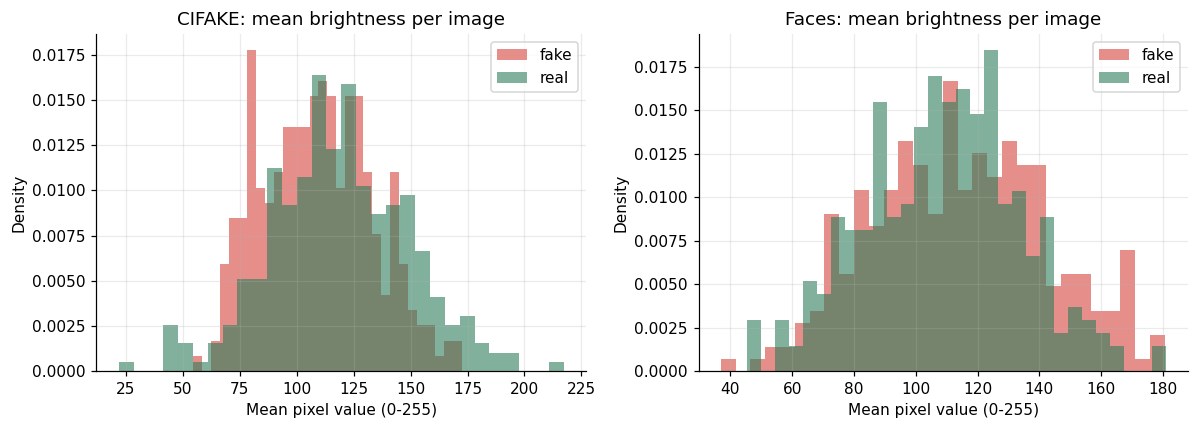

In [30]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 4))
axes = np.atleast_1d(axes)

for ax, dataset in zip(axes, DATASETS):
    for label in ["fake", "real"]:
        brightness = arrays[(dataset, label)].mean(axis=(1, 2, 3))   # one value per image
        ax.hist(brightness, bins=30, alpha=0.6, color=COLORS[label], label=label, density=True)
    ax.set_title(f"{dataset}: mean brightness per image")
    ax.set_xlabel("Mean pixel value (0-255)")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

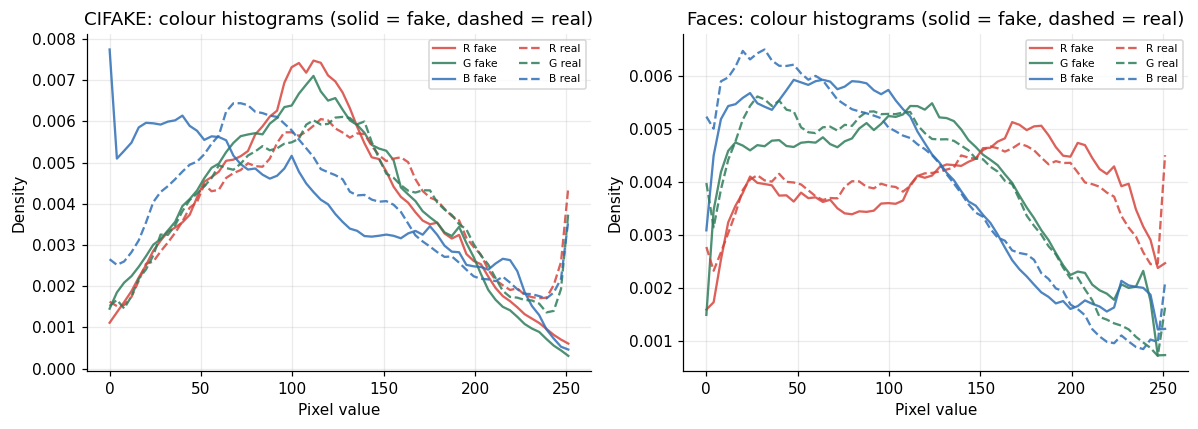

In [32]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 4))
axes = np.atleast_1d(axes)
channel_colors = {"R": "#d6453d", "G": "#2e7d5b", "B": "#2f6fb5"}

for ax, dataset in zip(axes, DATASETS):
    for label, style in [("fake", "-"), ("real", "--")]:
        arr = arrays[(dataset, label)]
        for i, ch in enumerate("RGB"):
            hist, edges = np.histogram(arr[..., i], bins=64, range=(0, 255), density=True)
            ax.plot(edges[:-1], hist, style, color=channel_colors[ch], alpha=0.85,
                    label=f"{ch} {label}")
    ax.set_title(f"{dataset}: colour histograms (solid = fake, dashed = real)")
    ax.set_xlabel("Pixel value")
    ax.set_ylabel("Density")
    ax.legend(ncol=2, fontsize=7)

plt.tight_layout()
plt.show()

## 6. Average image per class

The pixel-wise average of many images reveals **systematic structure** (for example centred faces, or a
consistent background). The difference map (fake minus real) shows where the two classes differ on average.

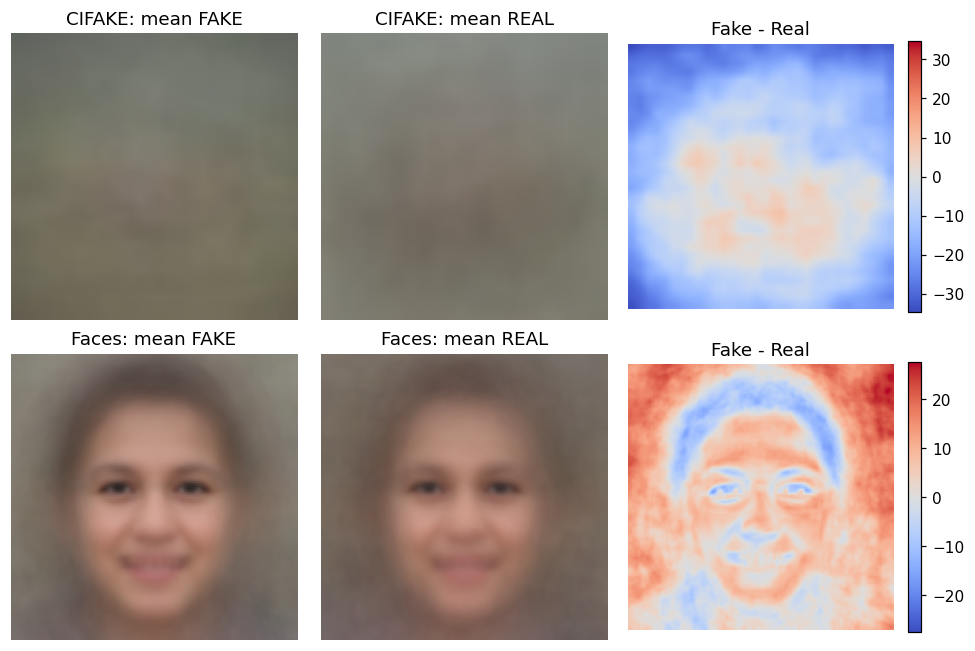

In [34]:
fig, axes = plt.subplots(len(DATASETS), 3, figsize=(9, 3 * len(DATASETS)))
axes = np.atleast_2d(axes)

for row, dataset in zip(axes, DATASETS):
    mean_fake = arrays[(dataset, "fake")].mean(axis=0)
    mean_real = arrays[(dataset, "real")].mean(axis=0)
    diff = (mean_fake - mean_real).mean(axis=2)          # grey-level difference

    row[0].imshow(mean_fake.astype(np.uint8)); row[0].set_title(f"{dataset}: mean FAKE")
    row[1].imshow(mean_real.astype(np.uint8)); row[1].set_title(f"{dataset}: mean REAL")
    lim = max(np.abs(diff).max(), 1e-6)
    im = row[2].imshow(diff, cmap="coolwarm", vmin=-lim, vmax=lim); row[2].set_title("Fake - Real")
    for ax in row: ax.axis("off")
    fig.colorbar(im, ax=row[2], fraction=0.046)

plt.tight_layout()
plt.show()

## 7. Frequency analysis (Fourier spectrum)

Generative models often leave **periodic traces in the frequency domain** (for example upsampling
patterns) that are invisible to the eye. We average the 2D log-magnitude spectrum of the grey-scale
images for each class. The centre of the plot is low frequencies, the borders are high frequencies.

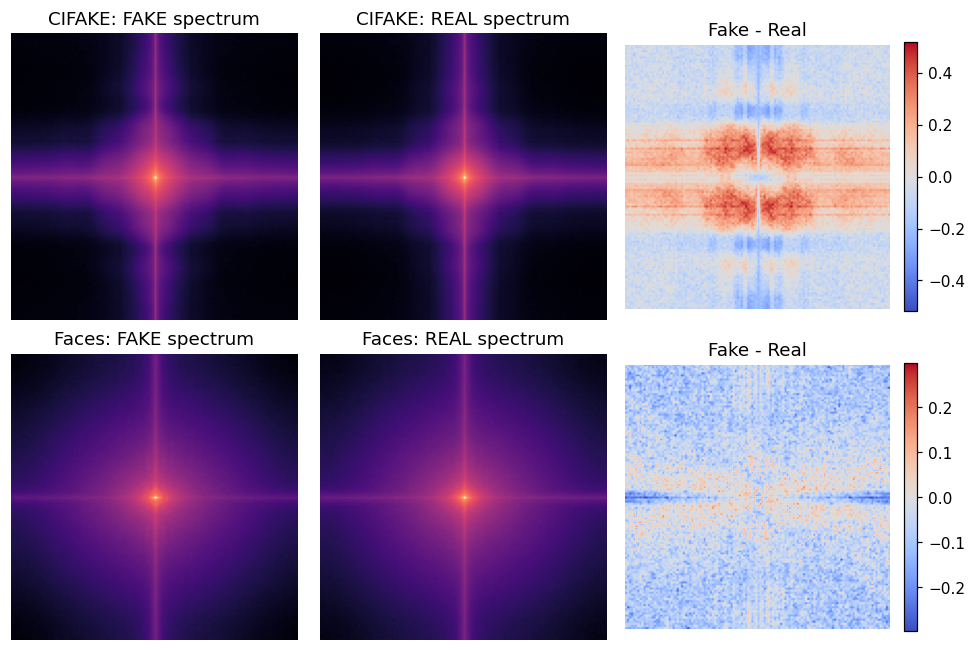

In [36]:
def mean_spectrum(arr):
    gray = arr.mean(axis=3)                                   # (N, H, W)
    spec = np.abs(np.fft.fftshift(np.fft.fft2(gray), axes=(1, 2)))
    return np.log1p(spec).mean(axis=0)

fig, axes = plt.subplots(len(DATASETS), 3, figsize=(9, 3 * len(DATASETS)))
axes = np.atleast_2d(axes)

for row, dataset in zip(axes, DATASETS):
    s_fake = mean_spectrum(arrays[(dataset, "fake")])
    s_real = mean_spectrum(arrays[(dataset, "real")])
    diff = s_fake - s_real
    lim = max(np.abs(diff).max(), 1e-6)

    row[0].imshow(s_fake, cmap="magma"); row[0].set_title(f"{dataset}: FAKE spectrum")
    row[1].imshow(s_real, cmap="magma"); row[1].set_title(f"{dataset}: REAL spectrum")
    im = row[2].imshow(diff, cmap="coolwarm", vmin=-lim, vmax=lim); row[2].set_title("Fake - Real")
    for ax in row: ax.axis("off")
    fig.colorbar(im, ax=row[2], fraction=0.046)

plt.tight_layout()
plt.show()

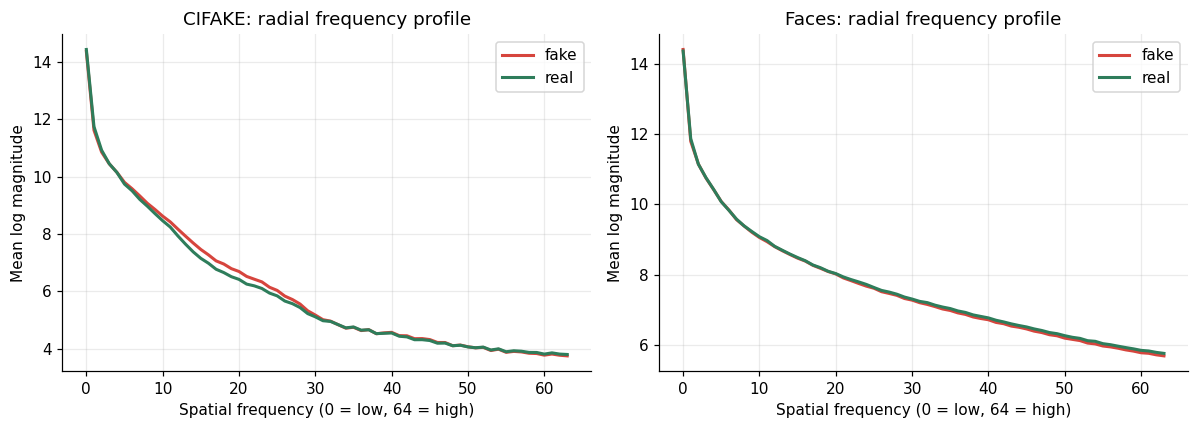

In [38]:
# Radially averaged spectrum: energy as a function of spatial frequency
def radial_profile(spec):
    h, w = spec.shape
    y, x = np.indices(spec.shape)
    r = np.hypot(x - w // 2, y - h // 2).astype(int)
    return np.bincount(r.ravel(), spec.ravel()) / np.bincount(r.ravel())

fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 4))
axes = np.atleast_1d(axes)

for ax, dataset in zip(axes, DATASETS):
    for label in ["fake", "real"]:
        prof = radial_profile(mean_spectrum(arrays[(dataset, label)]))[:64]
        ax.plot(prof, color=COLORS[label], label=label, lw=2)
    ax.set_title(f"{dataset}: radial frequency profile")
    ax.set_xlabel("Spatial frequency (0 = low, 64 = high)")
    ax.set_ylabel("Mean log magnitude")
    ax.legend()

plt.tight_layout()
plt.show()

## 8. Data integrity checks

Quick checks that protect the validity of the experiments: unreadable files, duplicated file names
across classes, and potential overlap between train and test.

In [42]:
# 8.1 Corrupted / unreadable images (checked on a sample for speed)
bad = []
check_paths = inventory.sample(min(3000, len(inventory)), random_state=SEED)["path"]
for p in check_paths:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception as e:
        bad.append((p, str(e)))

print(f"Checked {len(check_paths):,} images, unreadable: {len(bad)}")
for p, e in bad[:5]:
    print("  ", p, "->", e)

Checked 3,000 images, unreadable: 0


In [44]:
# 8.2 Train / test overlap by exact file content (hash) on a sample
import hashlib

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

overlap_report = []
for dataset in DATASETS:
    sub = inventory[inventory.dataset == dataset]
    train_p = sub[sub.split == "train"]["path"].sample(min(1500, (sub.split == "train").sum()), random_state=SEED)
    test_p = sub[sub.split == "test"]["path"].sample(min(1500, (sub.split == "test").sum()), random_state=SEED)
    train_hashes = {md5(p) for p in train_p}
    dup = sum(md5(p) in train_hashes for p in test_p)
    overlap_report.append({"dataset": dataset, "test_checked": len(test_p), "exact_duplicates_in_train_sample": dup})

display(pd.DataFrame(overlap_report))
print("Note: this only detects identical files inside the sampled subsets. It is a sanity check, not a proof of zero leakage.")

,dataset,test_checked,exact_duplicates_in_train_sample
0,CIFAKE,1500,0
1,Faces,1500,0


Note: this only detects identical files inside the sampled subsets. It is a sanity check, not a proof of zero leakage.


## 9. Summary table

In [46]:
summary = []
for dataset in DATASETS:
    sub = inventory[inventory.dataset == dataset]
    p = props[props.dataset == dataset]
    summary.append({
        "dataset": dataset,
        "total_images": len(sub),
        "splits": ", ".join(sorted(sub.split.unique())),
        "train_fake": int(((sub.split == "train") & (sub.label == "fake")).sum()),
        "train_real": int(((sub.split == "train") & (sub.label == "real")).sum()),
        "test_fake": int(((sub.split == "test") & (sub.label == "fake")).sum()),
        "test_real": int(((sub.split == "test") & (sub.label == "real")).sum()),
        "resolution": ", ".join(sorted((p["width"].astype(str) + "x" + p["height"].astype(str)).unique()))[:40],
        "mean_size_kb_fake": round(p[p.label == "fake"]["size_kb"].mean(), 1),
        "mean_size_kb_real": round(p[p.label == "real"]["size_kb"].mean(), 1),
    })

summary_df = pd.DataFrame(summary).set_index("dataset")
display(summary_df.T)

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(DATA_PROCESSED / "data_exploration_summary.csv")
inventory.drop(columns="path").groupby(["dataset", "split", "label"]).size().rename("count").to_csv(
    DATA_PROCESSED / "class_distribution.csv")
print("Saved to", DATA_PROCESSED)

dataset,CIFAKE,Faces
total_images,120000,140000
splits,"test, train","test, train, valid"
train_fake,50000,50000
train_real,50000,50000
test_fake,10000,10000
test_real,10000,10000
resolution,32x32,256x256
mean_size_kb_fake,0.9,27.7
mean_size_kb_real,0.9,28.1


Saved to C:\Users\21624\Desktop\deepfake_detection\data\processed


## 10. Conclusions

*Fill in with what you observed in your own run.*

**Structure**
- CIFAKE: `...` train / `...` test images, balanced (ratio `...`), 32 x 32 pixels.
- Faces: `...` train / `...` valid / `...` test images, balanced (ratio `...`), 256 x 256 pixels.

**Differences between fake and real**
- Brightness / colour: `...`
- File size: `...` (is there a bias a model could exploit?)
- Frequency spectrum: `...`

**Implications for modelling**
1. **Resolution gap:** CIFAKE is upscaled 4x to 128 x 128, while faces are downscaled 2x. A model trained on one sees very different pixel statistics than the other.
2. **Different content:** objects/animals vs human faces, so a detector can learn content-specific cues instead of general generation artifacts.
3. **Different generators:** each dataset is produced by a different generation method, which explains why a model trained on one fails on the other.

These points motivate the **cross-dataset evaluation** and the **combined model** in the next notebook.